# Riceify data pipeline notebook

This notebook pulls one real rice-field polygon in Japan, finds a low-cloud Sentinel-2 L2A scene, computes band summaries and NDVI-style features, and displays the result inline.

Data sources:
- MAFF Fude field polygons via Source Cooperative
- Sentinel-2 L2A via Microsoft Planetary Computer

In [1]:
from __future__ import annotations

import json
import math
import warnings
from dataclasses import dataclass
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer
import rasterio
from IPython.display import display
from pyproj import Geod, Transformer
from pystac_client import Client
from rasterio.features import geometry_mask
from rasterio.windows import from_bounds
from shapely import wkt
from shapely.geometry import mapping, shape
from shapely.ops import transform as shapely_transform

warnings.filterwarnings(
    "ignore",
    message="Setting the shape on a NumPy array has been deprecated.*",
    category=DeprecationWarning,
)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 200)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

In [2]:
FIDE_PARQUET_URL = (
    "https://data.source.coop/pacificspatial/field-polygon-jp/parquet/"
    "jp_field_polygons_2024.parquet"
)
PLANETARY_COMPUTER_STAC = "https://planetarycomputer.microsoft.com/api/stac/v1"
DEFAULT_BBOX = [138.86, 37.76, 138.92, 37.82]
DEFAULT_DATE_RANGE = "2024-06-01/2024-09-30"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

@dataclass
class SelectedField:
    polygon_uuid: str
    point_lng: float
    point_lat: float
    local_government_cd: str
    land_type_en: str
    area_m2: float
    geometry: dict


def geodesic_area_m2(geom) -> float:
    geod = Geod(ellps="GRS80")
    area, _ = geod.geometry_area_perimeter(geom)
    return abs(area)


def query_candidate_fields(bbox: list[float], limit: int = 5000) -> pd.DataFrame:
    west, south, east, north = bbox
    con = duckdb.connect()
    con.execute("INSTALL httpfs; LOAD httpfs;")
    con.execute("INSTALL spatial; LOAD spatial;")
    query = f"""
        SELECT
            polygon_uuid,
            land_type_en,
            point_lng,
            point_lat,
            local_government_cd,
            ST_AsText(GEOM) AS wkt
        FROM read_parquet('{FIDE_PARQUET_URL}')
        WHERE point_lng BETWEEN {west} AND {east}
          AND point_lat BETWEEN {south} AND {north}
          AND land_type_en = 'rice_field'
        LIMIT {limit}
    """
    return con.execute(query).fetchdf()


def select_field(bbox: list[float]) -> SelectedField:
    candidates = query_candidate_fields(bbox)
    if candidates.empty:
        raise RuntimeError(f"No MAFF Fude rice-field polygons found in bbox {bbox}.")

    candidates["geometry_obj"] = candidates["wkt"].map(wkt.loads)
    candidates["area_m2"] = candidates["geometry_obj"].map(geodesic_area_m2)
    candidates = candidates.sort_values("area_m2", ascending=False)
    field_row = candidates[
        (candidates["area_m2"] >= 1500) & (candidates["area_m2"] <= 20000)
    ].head(1)
    if field_row.empty:
        field_row = candidates.head(1)

    row = field_row.iloc[0]
    return SelectedField(
        polygon_uuid=row["polygon_uuid"],
        point_lng=float(row["point_lng"]),
        point_lat=float(row["point_lat"]),
        local_government_cd=str(row["local_government_cd"]),
        land_type_en=row["land_type_en"],
        area_m2=float(row["area_m2"]),
        geometry=mapping(row["geometry_obj"]),
    )


def search_sentinel_scene(bbox: list[float], date_range: str):
    catalog = Client.open(PLANETARY_COMPUTER_STAC)
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=date_range,
        query={"eo:cloud_cover": {"lt": 30}},
        max_items=25,
    )
    items = list(search.items())
    if not items:
        raise RuntimeError("No Sentinel-2 L2A scenes found for the selected area/date range.")
    items.sort(key=lambda item: item.properties.get("eo:cloud_cover", 1000))
    return planetary_computer.sign(items[0])


def field_geometry_in_crs(field_geom: dict, dst_crs) -> dict:
    geom = shape(field_geom)
    transformer = Transformer.from_crs("EPSG:4326", dst_crs, always_xy=True)
    return mapping(shapely_transform(transformer.transform, geom))


def read_asset_crop(asset_href: str, field_geom: dict, pad_meters: float = 40.0):
    with rasterio.open(asset_href) as src:
        geom_proj = field_geometry_in_crs(field_geom, src.crs)
        bounds = shape(geom_proj).bounds
        window = from_bounds(
            bounds[0] - pad_meters,
            bounds[1] - pad_meters,
            bounds[2] + pad_meters,
            bounds[3] + pad_meters,
            src.transform,
        ).round_offsets().round_lengths()
        data = np.array(src.read(1, window=window), dtype="float32", copy=True)
        transform = src.window_transform(window)
        nodata = src.nodata
        if nodata is not None:
            data[data == nodata] = np.nan

        mask = geometry_mask(
            [geom_proj],
            out_shape=data.shape,
            transform=transform,
            invert=True,
            all_touched=True,
        )
        return data, mask


def scale_reflectance(arr: np.ndarray) -> np.ndarray:
    return arr / 10000.0


def masked_stats(arr: np.ndarray, mask: np.ndarray) -> dict[str, float]:
    values = arr[mask & np.isfinite(arr)]
    if values.size == 0:
        return {"mean": math.nan, "median": math.nan, "min": math.nan, "max": math.nan}
    return {
        "mean": float(np.nanmean(values)),
        "median": float(np.nanmedian(values)),
        "min": float(np.nanmin(values)),
        "max": float(np.nanmax(values)),
    }


def normalized_difference(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    denom = a + b
    out = np.full(a.shape, np.nan, dtype="float32")
    valid = np.isfinite(a) & np.isfinite(b) & (np.abs(denom) > 1e-6)
    out[valid] = (a[valid] - b[valid]) / denom[valid]
    return out


def extract_features(item, field: SelectedField) -> tuple[pd.DataFrame, dict[str, np.ndarray]]:
    asset_names = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]
    features: dict[str, float | str] = {
        "field_id": field.polygon_uuid,
        "field_area_m2": field.area_m2,
        "field_center_lng": field.point_lng,
        "field_center_lat": field.point_lat,
        "local_government_cd": field.local_government_cd,
        "sentinel_item_id": item.id,
        "datetime": item.datetime.isoformat(),
        "scene_cloud_cover_pct": float(item.properties.get("eo:cloud_cover", np.nan)),
    }

    arrays: dict[str, np.ndarray] = {}
    masks: dict[str, np.ndarray] = {}

    for asset_name in asset_names:
        raw, mask = read_asset_crop(item.assets[asset_name].href, field.geometry)
        arr = scale_reflectance(raw)
        arrays[asset_name] = arr
        masks[asset_name] = mask
        stats = masked_stats(arr, mask)
        for stat_name, value in stats.items():
            features[f"{asset_name}_{stat_name}"] = value

    red = arrays["B04"]
    green = arrays["B03"]
    nir = arrays["B08"]
    ndvi = normalized_difference(nir, red)
    gndvi = normalized_difference(nir, green)

    b08_mean = features["B08_mean"]
    b11_mean = features["B11_mean"]
    features["NDWI_LSWI_mean"] = (
        (b08_mean - b11_mean) / (b08_mean + b11_mean)
        if np.isfinite(b08_mean) and np.isfinite(b11_mean) and abs(b08_mean + b11_mean) > 1e-6
        else math.nan
    )

    for band in ["B05", "B06", "B07"]:
        band_mean = features[f"{band}_mean"]
        features[f"RE_NDVI_{band}_mean"] = (
            (b08_mean - band_mean) / (b08_mean + band_mean)
            if np.isfinite(b08_mean) and np.isfinite(band_mean) and abs(b08_mean + band_mean) > 1e-6
            else math.nan
        )

    for name, arr in [("NDVI", ndvi), ("GNDVI", gndvi)]:
        stats = masked_stats(arr, masks["B08"])
        for stat_name, value in stats.items():
            features[f"{name}_{stat_name}"] = value

    return pd.DataFrame([features]), {
        "B02": arrays["B02"],
        "B03": arrays["B03"],
        "B04": arrays["B04"],
        "B05": arrays["B05"],
        "B06": arrays["B06"],
        "B07": arrays["B07"],
        "B08": arrays["B08"],
        "B8A": arrays["B8A"],
        "B11": arrays["B11"],
        "B12": arrays["B12"],
        "NDVI": ndvi,
        "mask_10m": masks["B08"],
        "mask_20m": masks["B11"],
    }


def preview_plot(preview_arrays: dict[str, np.ndarray]):
    red = preview_arrays["B04"]
    green = preview_arrays["B03"]
    blue = preview_arrays["B02"]
    rgb = np.dstack([red, green, blue])
    high = np.nanpercentile(rgb, 98)
    rgb = np.clip(rgb / high, 0, 1) if high > 0 else np.nan_to_num(rgb)

    ndvi = preview_arrays["NDVI"].copy()
    ndvi[~preview_arrays["mask_10m"]] = np.nan

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    axes[0].imshow(rgb)
    axes[0].set_title("Sentinel-2 RGB crop")
    axes[0].axis("off")

    im = axes[1].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    axes[1].set_title("NDVI inside selected field")
    axes[1].axis("off")
    fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    return fig


def plot_band_panels(preview_arrays: dict[str, np.ndarray]):
    band_specs = [
        ("B02", "Blue (490nm)", preview_arrays["mask_10m"], "Blues"),
        ("B03", "Green (560nm)", preview_arrays["mask_10m"], "Greens"),
        ("B04", "Red (665nm)", preview_arrays["mask_10m"], "Reds"),
        ("B08", "NIR (842nm)", preview_arrays["mask_10m"], "Purples"),
        ("B05", "Red edge 1", preview_arrays["mask_20m"], "cividis"),
        ("B06", "Red edge 2", preview_arrays["mask_20m"], "cividis"),
        ("B07", "Red edge 3", preview_arrays["mask_20m"], "cividis"),
        ("B11", "SWIR 1", preview_arrays["mask_20m"], "magma"),
        ("B12", "SWIR 2", preview_arrays["mask_20m"], "magma"),
    ]

    fig, axes = plt.subplots(3, 3, figsize=(12, 11), constrained_layout=True)
    for ax, (band_name, title, mask, cmap) in zip(axes.flat, band_specs):
        arr = preview_arrays[band_name].copy()
        arr[~mask] = np.nan
        low = np.nanpercentile(arr, 2)
        high = np.nanpercentile(arr, 98)
        im = ax.imshow(arr, cmap=cmap, vmin=low, vmax=high)
        ax.set_title(title)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    return fig


## Run the extraction

The defaults target a rice-heavy area near Niigata. You can change `bbox` or `date_range` in the next cell and rerun.

,polygon_uuid,land_type_en,area_m2,point_lng,point_lat,local_government_cd,item_id,datetime,cloud_cover_pct,collection
0,472bcb5b-8130-494b-93e8-289344678125,rice_field,18477.232312,138.910969,37.771595,151084,S2A_MSIL2A_20240620T012701_R074_T54SUG_2024062...,2024-06-20T01:27:01.024000+00:00,0.618286,sentinel-2-l2a


,value
field_id,472bcb5b-8130-494b-93e8-289344678125
field_area_m2,18477.232312
field_center_lng,138.910969
field_center_lat,37.771595
local_government_cd,151084
sentinel_item_id,S2A_MSIL2A_20240620T012701_R074_T54SUG_2024062...
datetime,2024-06-20T01:27:01.024000+00:00
scene_cloud_cover_pct,0.618286
B02_mean,0.161189
B02_median,0.159500


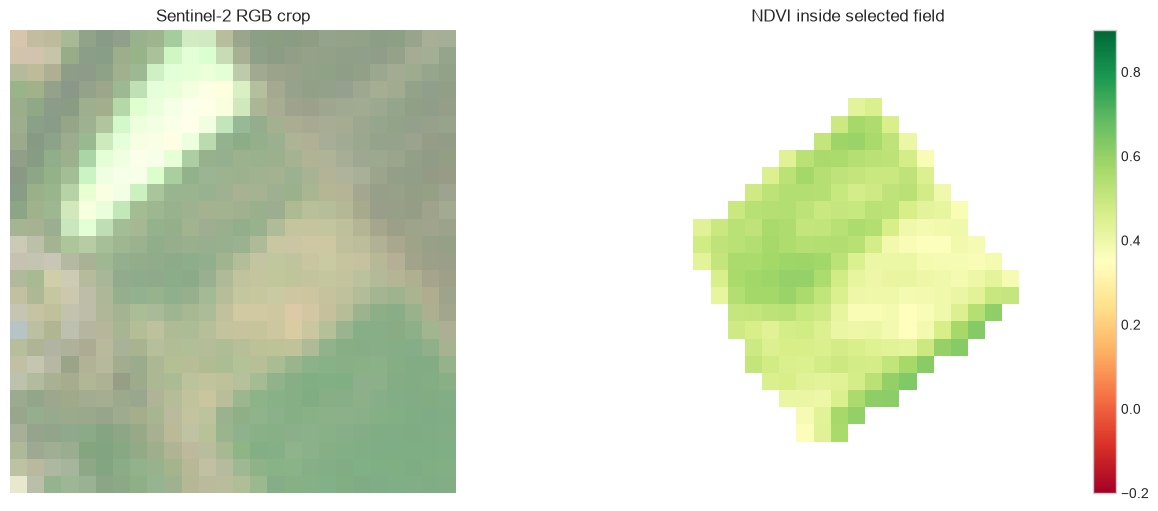

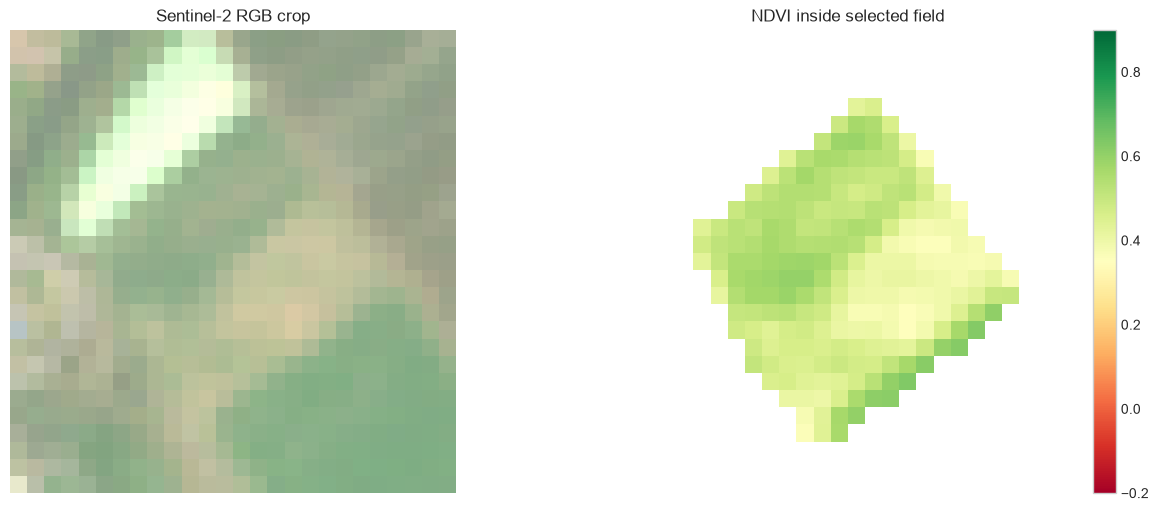

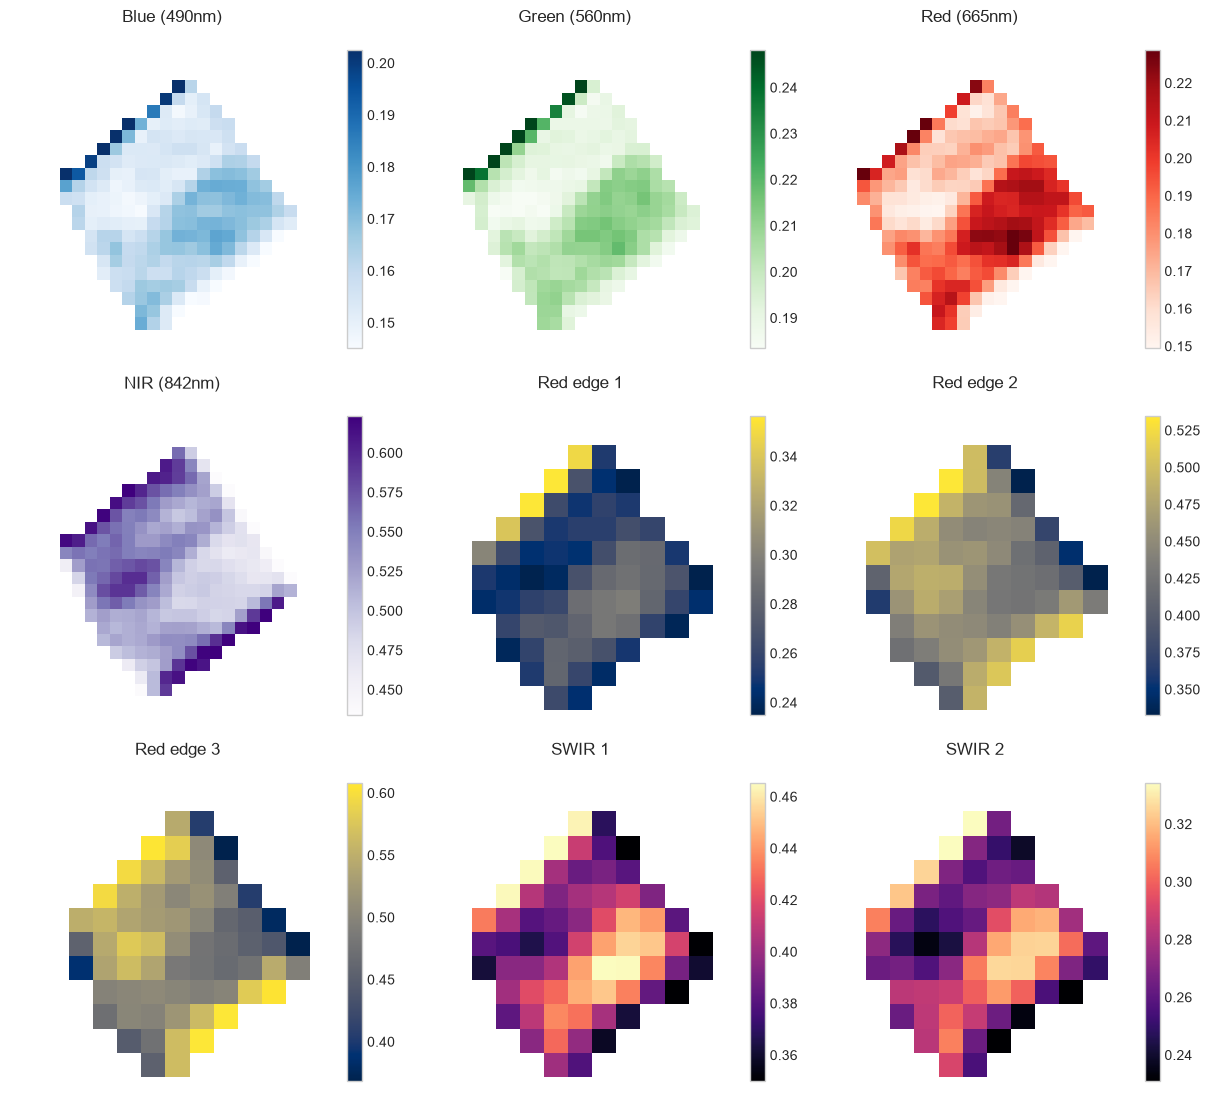

In [3]:
bbox = DEFAULT_BBOX
date_range = DEFAULT_DATE_RANGE

field = select_field(bbox)
item = search_sentinel_scene(bbox, date_range)
features, preview_arrays = extract_features(item, field)

metadata = {
    "field": {
        "polygon_uuid": field.polygon_uuid,
        "land_type_en": field.land_type_en,
        "area_m2": field.area_m2,
        "point_lng": field.point_lng,
        "point_lat": field.point_lat,
        "local_government_cd": field.local_government_cd,
    },
    "sentinel_scene": {
        "item_id": item.id,
        "datetime": item.datetime.isoformat(),
        "cloud_cover_pct": item.properties.get("eo:cloud_cover"),
        "collection": item.collection_id,
    },
    "sources": {
        "field_polygons": FIDE_PARQUET_URL,
        "sentinel_stac": PLANETARY_COMPUTER_STAC,
    },
}

feature_collection = {
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "properties": metadata["field"],
            "geometry": field.geometry,
        }
    ],
}

(OUTPUT_DIR / "selected_field.geojson").write_text(json.dumps(feature_collection, indent=2), encoding="utf-8")
(OUTPUT_DIR / "field_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
features.to_csv(OUTPUT_DIR / "field_band_features.csv", index=False)

fig = preview_plot(preview_arrays)
fig.savefig(OUTPUT_DIR / "field_rgb_ndvi.png", dpi=180)

summary_df = pd.DataFrame([metadata["field"]]).join(pd.DataFrame([metadata["sentinel_scene"]]))
display(summary_df)
display(features.T.rename(columns={0: "value"}))
preview_fig = preview_plot(preview_arrays)
band_fig = plot_band_panels(preview_arrays)
band_fig.savefig(OUTPUT_DIR / "field_band_panels.png", dpi=180)
plt.show()

## What this example is and is not

This notebook currently selects one single MAFF rice-field polygon and one low-cloud Sentinel-2 scene over that field.

The band set here is enough for a solid first vegetation-health pipeline, especially with `B04`, `B08`, the red-edge bands `B05`/`B06`/`B07`, and the SWIR bands `B11`/`B12`.
For rice yield prediction, these bands are a strong start but usually work best when we add time series features across the season, plus weather and possibly Sentinel-1 SAR.

## Saved outputs

Running the notebook also refreshes:
- `outputs/selected_field.geojson`
- `outputs/field_metadata.json`
- `outputs/field_band_features.csv`
- `outputs/field_rgb_ndvi.png`
- `outputs/field_band_panels.png`